# 02 – Baseline: TF-IDF + Logistic Regression   

In [2]:
# ═══ SETUP ═══
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, confusion_matrix
)
from sklearn.pipeline import Pipeline
import joblib

from src.modeling.preprocess import (
    preprocess, aggregate_by_filing, train_val_test_split, clean_text
)

sns.set_style("whitegrid")   

## 1. Load & Preprocess   

In [3]:
import pyarrow.parquet as pq

target_dir = '../data/samples'
parquet_path = target_dir + "/financial_reports_firm_sample.parquet"
pf = pq.ParquetFile(parquet_path)
data = next(pf.iter_batches(batch_size=20)).to_pandas()

In [4]:
data.head(5)

,cik,sentence,section,section_name,labels,filingDate,name,docID,sentenceID,sentenceCount,...,exchanges,entityType,sic,stateOfIncorporation,tickerCount,acceptanceDateTime,form,reportDate,returns,split
0,0000001750,ITEM 1.BUSINESS General AAR CORP. and its subs...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_0,1,...,[NYSE],operating,3720,DE,1,2020-07-21T17:19:15.000Z,10-K,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train
1,0000001750,"AAR was founded in 1951, organized in 1955 and...",0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_1,2,...,[NYSE],operating,3720,DE,1,2020-07-21T17:19:15.000Z,10-K,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train
2,0000001750,We are a diversified provider of products and ...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_2,3,...,[NYSE],operating,3720,DE,1,2020-07-21T17:19:15.000Z,10-K,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train
3,0000001750,Fiscal 2020 began with strategic initiatives f...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_3,4,...,[NYSE],operating,3720,DE,1,2020-07-21T17:19:15.000Z,10-K,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train
4,0000001750,Our momentum from a successful fiscal 2019 car...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_4,5,...,[NYSE],operating,3720,DE,1,2020-07-21T17:19:15.000Z,10-K,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train


In [5]:
data.loc[0:12, 'sentence'].apply(lambda x: clean_text(x))

0     item 1.business general aar corp. and its subs...
1     aar was founded in organized in and reincorpor...
2     we are a diversified provider of products and ...
3     fiscal began with strategic initiatives focuse...
4     our momentum from a successful fiscal carried ...
5     we also realized the positive impact our effor...
6     we succeeded in enhancing customer relationshi...
7     in fiscal we were awarded a new $118 million c...
8     this award demonstrates the power of our integ...
9     we were also awarded new long-term contracts a...
10    our strategy to exit the capital-intensive con...
11    as we continued to successfully execute on our...
12    sales had increased $166.4 million or 11.2% ov...
Name: sentence, dtype: object

In [3]:
target_dir = '../data/samples'
# --- Charger ---
df = pd.read_parquet(target_dir + "/financial_reports_firm_sample.parquet")
df = preprocess(df)
print(f"After preprocessing: {df.shape}")   
print(f"Raw sentences: {len(df)}")
print(f"Unique filings: {df['docID'].nunique()}")
print(f"Unique firms: {df['cik'].nunique()}")
print(df.groupby('split')['cik'].nunique())   

After preprocessing: (1295995, 28)
Raw sentences: 1295995
Unique filings: 1131
Unique firms: 84
split
test        20
train       48
validate    16
Name: cik, dtype: int64


In [4]:
df

,cik,sentence,section,section_name,labels,filingDate,name,docID,sentenceID,sentenceCount,...,reportDate,returns,split,label_1d,label_5d,label_30d,ret_1d,ret_5d,ret_30d,word_count
0,0000001750,item 1.business general aar corp. and its subs...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_0,1,...,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train,0,1,0,0.04508,-0.025838,0.058274,25
1,0000001750,aar was founded in organized in and reincorpor...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_1,2,...,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train,0,1,0,0.04508,-0.025838,0.058274,12
2,0000001750,we are a diversified provider of products and ...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_2,3,...,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train,0,1,0,0.04508,-0.025838,0.058274,18
3,0000001750,fiscal began with strategic initiatives focuse...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_3,4,...,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train,0,1,0,0.04508,-0.025838,0.058274,21
4,0000001750,our momentum from a successful fiscal carried ...,0,1,"{'1d': 0, '30d': 0, '5d': 1}",2020-07-21,AAR CORP,0000001750_10-K_2020,0000001750_10-K_2020_section_1_4,5,...,2020-05-31,"{'1d': {'closePriceEndDate': 19.0100002289, 'c...",train,0,1,0,0.04508,-0.025838,0.058274,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295990,0001621227,attestation report of the registered public ac...,12,9A,"{'1d': 0, '30d': 0, '5d': 0}",2017-03-13,Adaptimmune Therapeutics PLC,0001621227_10-K_2016,0001621227_10-K_2016_section_9A_8,1343096,...,2016-12-31,"{'1d': {'closePriceEndDate': 4.7300000191, 'cl...",test,0,0,0,0.02603,0.002169,0.251627,8
1295991,0001621227,this report does not include an attestation re...,12,9A,"{'1d': 0, '30d': 0, '5d': 0}",2017-03-13,Adaptimmune Therapeutics PLC,0001621227_10-K_2016,0001621227_10-K_2016_section_9A_9,1343097,...,2016-12-31,"{'1d': {'closePriceEndDate': 4.7300000191, 'cl...",test,0,0,0,0.02603,0.002169,0.251627,21
1295992,0001621227,changes in internal control over financial rep...,12,9A,"{'1d': 0, '30d': 0, '5d': 0}",2017-03-13,Adaptimmune Therapeutics PLC,0001621227_10-K_2016,0001621227_10-K_2016_section_9A_10,1343098,...,2016-12-31,"{'1d': {'closePriceEndDate': 4.7300000191, 'cl...",test,0,0,0,0.02603,0.002169,0.251627,7
1295993,0001621227,there has been no change in our internal contr...,12,9A,"{'1d': 0, '30d': 0, '5d': 0}",2017-03-13,Adaptimmune Therapeutics PLC,0001621227_10-K_2016,0001621227_10-K_2016_section_9A_11,1343099,...,2016-12-31,"{'1d': {'closePriceEndDate': 4.7300000191, 'cl...",test,0,0,0,0.02603,0.002169,0.251627,44


## 2. Aggregate to Filing Level   

In [5]:
# --- All sections combined ---
df_all = aggregate_by_filing(df)
print(f"\n[Filing-level, ALL sections] {len(df_all)} filings")
print(df_all["label_30d"].value_counts(normalize=True))

del df


[Filing-level, ALL sections] 1131 filings
label_30d
0    0.530504
1    0.469496
Name: proportion, dtype: float64


## 3. Train/Validation/Test Split (by firm)   

In [6]:
# Split on the filing-level dataframe using official firm-level splits
train_all, val_all, test_all = train_val_test_split(df_all)

Train: 977 filings, 48 firms
Val:   42 filings, 16 firms
Test:  112 filings, 20 firms


## 4. TF-IDF + LogReg (Filing-Level, ALL Sections)   

In [7]:
def run_tfidf_logreg(train_df, test_df, max_features=10000, ngram_range=(1,2), C=1.0):
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=max_features,
            ngram_range=ngram_range,
            stop_words="english",
            min_df=2
        )),
        ("clf", LogisticRegression(
            C=C, class_weight="balanced", max_iter=1000, random_state=42
        ))
    ])
    pipe.fit(train_df["text"], train_df["label_30d"])
    y_pred = pipe.predict(test_df["text"])
    y_prob = pipe.predict_proba(test_df["text"])[:, 1]

    metrics = {
        "accuracy": accuracy_score(test_df["label_30d"], y_pred),
        "precision": precision_score(test_df["label_30d"], y_pred),
        "recall": recall_score(test_df["label_30d"], y_pred),
        "f1": f1_score(test_df["label_30d"], y_pred),
        "roc_auc": roc_auc_score(test_df["label_30d"], y_prob),
    }
    return pipe, metrics 

## 4. Evaluation   

              precision    recall  f1-score   support

positive (0)       0.54      0.49      0.51        53
negative (1)       0.58      0.63      0.60        59

    accuracy                           0.56       112
   macro avg       0.56      0.56      0.56       112
weighted avg       0.56      0.56      0.56       112

ROC-AUC: 0.5859


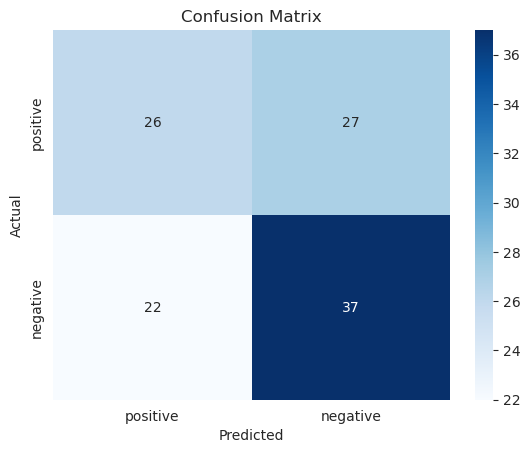

In [8]:
# --- ALL sections ---
pipe_all, metrics_all = run_tfidf_logreg(train_all, test_all)

print(classification_report(test_all["label_30d"], pipe_all.predict(test_all["text"]),
                            target_names=["positive (0)", "negative (1)"]))
print(f"ROC-AUC: {roc_auc_score(test_all['label_30d'], pipe_all.predict_proba(test_all['text'])[:, 1]):.4f}")

# Confusion matrix
cm = confusion_matrix(test_all["label_30d"], pipe_all.predict(test_all["text"]))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["positive", "negative"],
            yticklabels=["positive", "negative"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()   

## 5. GridSearch (hyperparameter tuning)   

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", min_df=2)),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))
])

param_grid = {
    "tfidf__max_features": [5000, 10000, 20000],
    "tfidf__ngram_range": [(1,1), (1,2)],
    "clf__C": [0.1, 1.0, 10.0]
}

grid = GridSearchCV(pipe, param_grid, cv=3, scoring="f1", n_jobs=2)
grid.fit(train_all["text"], train_all["label_30d"])

print(f"Best params: {grid.best_params_}")
print(f"Best CV F1: {grid.best_score_:.4f}")

# Evaluate best model on test
y_pred_best = grid.predict(test_all["text"])
y_prob_best = grid.predict_proba(test_all["text"])[:, 1]
print(f"\nTest F1: {f1_score(test_all['label_30d'], y_pred_best):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(test_all['label_30d'], y_prob_best):.4f}")   

print(classification_report(test_all["label_30d"], y_pred_best,
                            target_names=["positive (0)", "negative (1)"]))

Best params: {'clf__C': 0.1, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 2)}
Best CV F1: 0.5180

Test F1: 0.4952
Test ROC-AUC: 0.5411
              precision    recall  f1-score   support

positive (0)       0.50      0.62      0.55        53
negative (1)       0.57      0.44      0.50        59

    accuracy                           0.53       112
   macro avg       0.53      0.53      0.52       112
weighted avg       0.53      0.53      0.52       112



## 7. Top Features (SHAP-like for LogReg)   

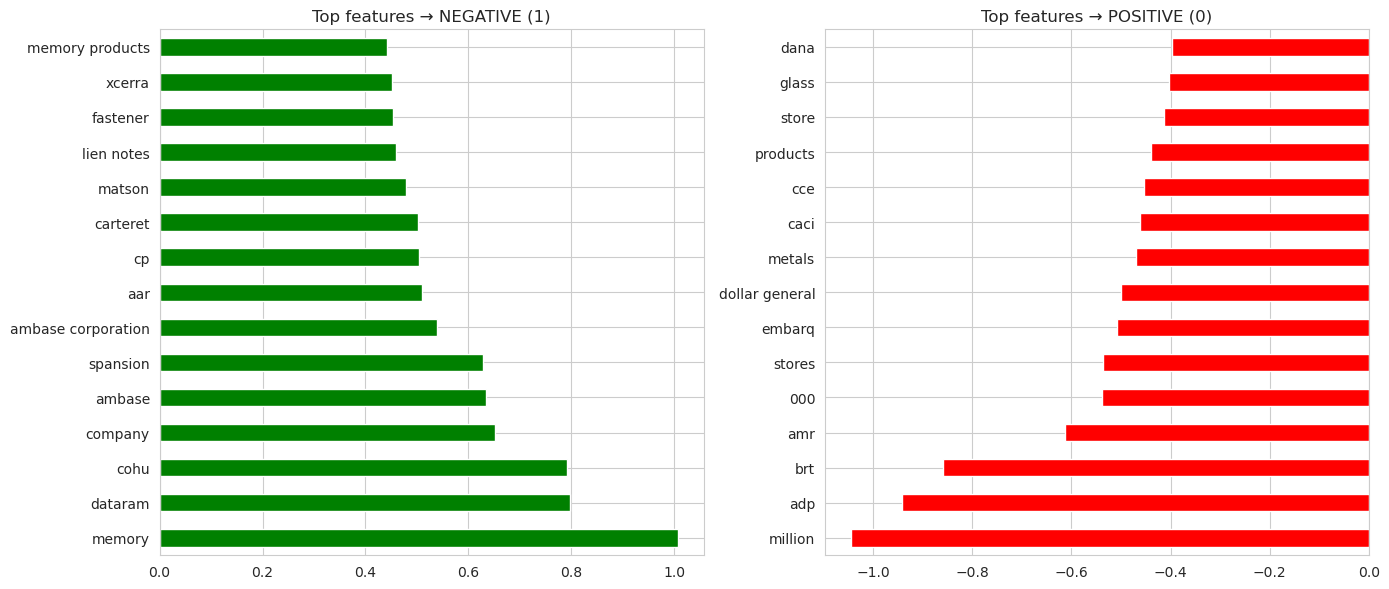

In [10]:
tfidf = pipe_all.named_steps["tfidf"]
clf = pipe_all.named_steps["clf"]
features = tfidf.get_feature_names_out()
coef = pd.Series(clf.coef_[0], index=features)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
coef.nlargest(15).plot(kind="barh", ax=axes[0], color="green")
axes[0].set_title("Top features → NEGATIVE (1)")
coef.nsmallest(15).plot(kind="barh", ax=axes[1], color="red")
axes[1].set_title("Top features → POSITIVE (0)")
plt.tight_layout()
plt.show()   

## 7. Confusion Matrix   

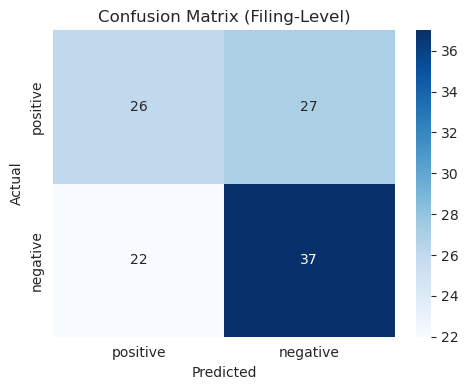

In [11]:
y_pred = pipe_all.predict(test_all["text"])
cm = confusion_matrix(test_all["label_30d"], y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["positive", "negative"],
            yticklabels=["positive", "negative"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix (Filing-Level)")
plt.tight_layout()
plt.show()   

## 8. Save artifacts   

In [12]:
import os
os.makedirs("../models", exist_ok=True)

model = pipe_all
vectorizer = pipe_all.named_steps["tfidf"]

joblib.dump(model, "../models/logreg_baseline.pkl")
joblib.dump(vectorizer, "../models/tfidf_vectorizer.pkl")
print("✓ Saved model and vectorizer")

✓ Saved model and vectorizer
